# 06 – Convolutional network (CNN) + distillation (proton)

## 1. Introduction

Instead of formulas, here a **convolutional neural network** learns the shape, without a predefined functional form.
For every momentum, the network outputs a full probability map on the $(z', r)$ grid. It is trained with the same detector convolution and
likelihood as the GFlash formula (01) and the MLP (05), so they are directly comparable.

**How does the CNN (convolutional decoder) work?** From the momentum, the network builds a small $8 \times 2$ "sketch" image, then in four steps
upsamples it by a factor of two and refines it with convolutional filters after each step, until it reaches the $128 \times 32$ grid.
The momentum enters every step as a modulation (FiLM). It is like a **painter starting from a rough sketch** and adding, step by step,
ever finer details. The convolution also naturally handles smoothness between neighbouring cells.

**How large should the network be?** For the MLP (05) the architecture was chosen by a validation search. Training the CNN is about 4 times more expensive, so
here we **do not search**: the architecture is **derived** from the task and the data (section 3), then **verified with a single training run**
to have sufficient capacity (4b): the validation NLL must not be detectably worse than that of the validated-sufficient MLP.

**Distillation (symbolic regression):** the trained network is "translated" into an analytic formula, just as for the MLP.

**Unified comparison (section 7):** the CNN and CNN-formula $r_{95}$ are added to the previous shapes (GFlash, envelope, drop, MLP, MLP-formula).

> **Copy of the report notebook `06_cnn_proton.ipynb`** (shape-form). Its cells are unchanged; only the data path is absolute, and the report's
> saved models are loaded from `results/`. **Section 8** adds the shower-shape formula of shape-form-particle next to the network and its distilled formula.

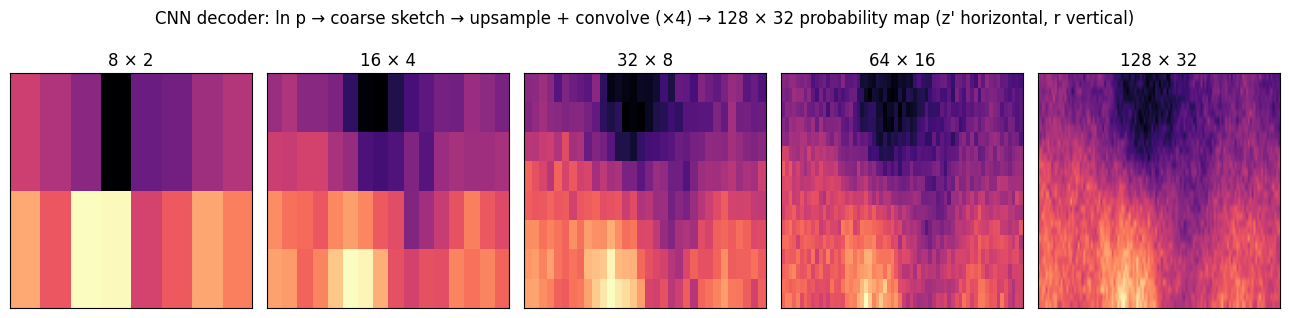

In [1]:
import matplotlib.pyplot as plt, torch, torch.nn.functional as F
torch.manual_seed(3)
img = torch.randn(1, 1, 8, 2) + torch.tensor([[[[2.0, 0.5]] * 3 + [[1.0, 0.2]] * 5]]).reshape(1, 1, 8, 2)
stages = [img]
for _ in range(4):
    stages.append(F.interpolate(stages[-1], scale_factor=2, mode="bilinear") + 0.15 * torch.randn(1, 1, *[2 * s for s in stages[-1].shape[2:]]))
fig, axes = plt.subplots(1, 5, figsize=(13, 3.2))
for ax, s in zip(axes, stages):
    ax.imshow(s[0, 0].T.numpy(), origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"{s.shape[2]} × {s.shape[3]}"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("CNN decoder: ln p → coarse sketch → upsample + convolve (×4) → 128 × 32 probability map (z' horizontal, r vertical)")
plt.tight_layout(); plt.show()

## 2. Loading the data

In [2]:
PARTICLES = ['proton']
DATA_DIR = "/home/user/data/simulations/regression-proton/"          # a CSV-k helye
OUT_DIR = "results"        # models and exports are stored here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: /home/user/data/simulations/regression-proton/ | output: results


In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

proton: 99925 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69946, val 14987, test 14992

===== proton =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54740548 entries, 0 to 54740547
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                

,count,mean,std,min,25%,50%,75%,max
event_number,54740548.0,1.061527e+05,7.737650e+04,3.000000e+00,5.248700e+04,1.050650e+05,1.577730e+05,2.119982e+06
cellID,54740548.0,2.078115e+09,1.471819e+09,4.212000e+03,7.136951e+08,1.745523e+09,3.306567e+09,5.063386e+09
x,54740548.0,8.340518e+00,1.308310e+03,-2.596035e+03,-1.032024e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,54740548.0,-3.721223e+00,1.311835e+03,-2.599800e+03,-1.036200e+03,-2.620000e+01,1.036200e+03,2.599800e+03
z,54740548.0,4.087755e+03,2.839532e+02,3.662400e+03,3.867400e+03,4.031400e+03,4.277400e+03,4.871900e+03
x_local,54740548.0,-4.207020e+01,2.241171e+02,-4.896420e+03,-1.444550e+02,-3.088325e+01,6.947679e+01,2.979718e+03
y_local,54740548.0,1.054415e-01,2.235098e+02,-3.319625e+03,-1.091375e+02,0.000000e+00,1.090265e+02,3.238695e+03
z_local,54740548.0,4.406571e+02,3.025983e+02,-2.931879e+03,2.039936e+02,3.921629e+02,6.374536e+02,2.667495e+03
x_trans,54740548.0,6.120635e-02,2.520863e+02,-4.887696e+03,-1.398834e+02,0.000000e+00,1.412087e+02,5.140408e+03
y_trans,54740548.0,3.625353e-03,2.520673e+02,-4.894655e+03,-1.405741e+02,0.000000e+00,1.403782e+02,5.147369e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,186640,2823563636,-1387.531982,-2147.199951,4379.899902,-130.723225,-378.459188,761.351211,-463.007620,-103.890706,...,4.238810e-08,1200.353271,17.044954,0.549644,-1.997623,17,neutron,1,neutron,gamma;gamma
1,132450,163584116,132.927994,2551.199951,4277.399902,69.697194,210.840800,750.914462,-152.802091,460.011513,...,6.959773e-08,574.963501,13.259551,0.524659,1.441496,13,neutron,1,neutron,proton;proton
2,1436,2307335028,-830.135010,-175.800003,4359.399902,-226.855893,-0.924198,665.431786,90.170637,18.004689,...,6.916019e-04,14.909340,16.654422,0.197399,-2.954562,16,proton,1,neutron,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
3,118990,608834164,835.135010,-1339.199951,3887.899902,-119.737264,179.827552,193.795084,146.963886,108.548892,...,1.211111e-08,1620.073486,19.433977,0.411175,-1.112347,19,neutron,1,neutron,NaN
4,49113,4412592500,984.348999,1440.199951,4236.399902,-218.178821,-147.723526,531.631196,141.541496,-50.457615,...,2.290001e-05,165.507782,17.042273,0.437355,1.044127,17,neutron,1,neutron,gamma;gamma;gamma


## 3. The model

### What do we fit, and what affects training?

**Input:** only $\ln p$ (`incoming_momentum`); the $(z, r)$ position is provided by coordinate channels at every step. **Output:** the full $(z', r)$ map.
Training minimises the same likelihood as for the formulas and the MLP:
- $z'$ = `z_local`, $r$ = `hypot(x_local, y_local)`, weight `energy` (normalised per event), grouped by `event_number`.
- **Affected by:** the detector convolution (`incoming_theta`, `incoming_phi`, cell size), the back-face truncation ($z_b$), the cuts.
- **Smoothness penalty** (`smooth=1e-4`), `epochs=60`, `lr=3e-3`, Adam, early stopping on the validation NLL: all the same as for the MLP.

### Deriving the architecture (instead of a hyperparameter search)

The task: produce from a **scalar** ($\ln p$) a $128 \times 32$ map **describing a smooth 3D body of revolution**. Four rules follow:

| # | rule | justification from the task | result |
|---|---|---|---|
| R1 | **Initial sketch = degrees of freedom of the formulas** | Every formula (GFlash, cylinder) describes a few longitudinal segments (rise, maximum, fall-off) and 2 lateral components (core + tail). The sketch has 2 cells in $r$ (core/tail) and 8 segments in $z'$ (~206 mm = ~10 $X_0$ / ~1.2 $\lambda_{int}$). | $8 \times 2$, global (fully connected) layer: the whole shape is coherent |
| R2 | **Upsampling steps = resolution missing to reach the grid** | $N_R / 2 = 32/2 = 16 = 2^4$, and also $N_Z / 8 = 16$. | 4 steps, ×2 bilinear upsampling + 3×3 convolution |
| R3 | **The local receptive field must cover the measurement scale** | The smallest scale still constrained by the data is the cell (~48 mm ≈ 3.7 $z'$ cells) and the layer spacing (20.5 mm). The local receptive field of the last level's 3×3 convolutions must be larger, otherwise the network may learn sub-cell artefacts. | computed in the code (below) |
| R4 | **Channel count: halved when the resolution doubles; capacity matched to the MLP's order of magnitude** | The input information is a single scalar, so the output has few degrees of freedom; for the MLP 3k parameters were already saturated. Thanks to the shared convolutional weights of the CNN, 1–2 orders of magnitude more parameters are safe: there is no per-event freedom, and overfitting would show on validation. The lower bound is the 8 groups of GroupNorm. | $48 \to 48 \to 32 \to 32 \to 16$ channels, embedding 64 |

**Check (4b):** after a single training run, (a) the train–val gap should be small, (b) the paired validation NLL should be at most one standard error
worse than that of the validated-sufficient MLP. If (b) fails, **a single pre-registered step** follows: doubling every channel count (upper branch of R4) and
retraining. This is not a search but a predefined fallback.

In [4]:
class FiLMConv(nn.Module):
    """3x3 convolution + normalisation, modulated by the momentum embedding (FiLM)."""

    def __init__(self, cin, cout, emb):
        super().__init__()
        self.conv, self.norm, self.film = nn.Conv2d(cin, cout, 3, padding=1), nn.GroupNorm(8, cout), nn.Linear(emb, 2 * cout)

    def forward(self, x, e):
        g, b = self.film(e).chunk(2, 1)
        return F.silu(self.norm(self.conv(x)) * (1 + g[..., None, None]) + b[..., None, None])


class ConvModel(nn.Module):
    """ln p -> 8x2 sketch -> 4 x (upsample x2 + FiLM conv) -> 128x32 logits -> softmax."""

    def __init__(self, emb=64, chans=(48, 48, 32, 32, 16)):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(1, emb), nn.SiLU(), nn.Linear(emb, emb), nn.SiLU())
        self.fc = nn.Linear(emb, chans[0] * (N_Z // 16) * (N_R // 16))
        self.blocks = nn.ModuleList([FiLMConv(chans[i] + 2, chans[i + 1], emb) for i in range(4)])
        self.head = nn.Conv2d(chans[-1] + 2, 1, 1)
        self.c0 = chans[0]

    @staticmethod
    def coords(x):                                             # (z, r) position channels
        B, _, h, w = x.shape
        zz = torch.linspace(-1, 1, h, device=x.device)[:, None].expand(h, w)
        rr = torch.linspace(0, 1, w, device=x.device)[None, :].expand(h, w)
        return torch.cat([x, torch.stack([zz, rr])[None].expand(B, -1, -1, -1)], 1)

    def forward(self, lnp):
        e = self.embed((lnp / 3)[:, None])
        x = self.fc(e).view(len(lnp), self.c0, N_Z // 16, N_R // 16)
        for blk in self.blocks:
            x = blk(self.coords(F.interpolate(x, scale_factor=2, mode="bilinear")), e)
        logits = self.head(self.coords(x)).squeeze(1)
        return F.log_softmax(logits.reshape(len(lnp), -1), 1).reshape(len(lnp), N_Z, N_R)


CHANS = (48, 48, 32, 32, 16)
make_model = lambda chans=CHANS: ConvModel(chans=chans).to(DEVICE)

# R1-R3 checked numerically from the grid and the detector geometry
n_up = int(math.log2(N_R // 2))
rf = 1 + 2 * sum(2 ** k for k in range(n_up))           # local receptive field of the stacked 3x3 convs, in final z' cells
print(f"sketch: {N_Z // 2 ** n_up} x {N_R // 2 ** n_up} cells  ({(Z_MAX - Z_MIN) / (N_Z // 2 ** n_up):.0f} mm per depth stage)")
print(f"upsampling steps: {n_up}  |  local receptive field: {rf} z' cells = {rf * DZ:.0f} mm  (cell ~48 mm, layer 20.5 mm)")
print("parameters:", sum(p.numel() for p in make_model().parameters()))

sketch: 8 x 2 cells  (206 mm per depth stage)
upsampling steps: 4  |  local receptive field: 31 z' cells = 400 mm  (cell ~48 mm, layer 20.5 mm)
parameters: 121939


## 4. Training

Same likelihood and settings as for the MLP. The model is saved to `results/proton/cnn.pt`, also every 5 epochs:
an interrupted training resumes when the cell is re-run, a completed one is only loaded.

loaded finished model from results/proton/cnn.pt


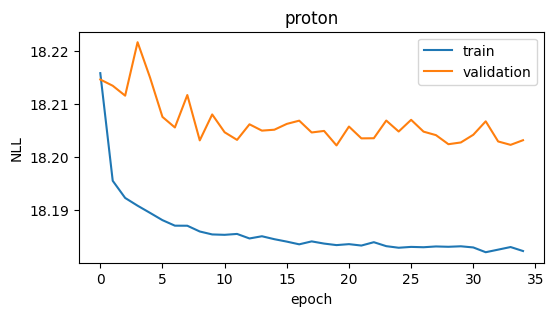

In [5]:
particle = PARTICLES[0]
data = DATA[particle]
NETS = {particle: make_model()}
hist = fit(NETS[particle], data, f"{OUT_DIR}/{particle}/cnn.pt", epochs=60, lr=3e-3, smooth=1e-4)
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.title(particle); plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 4b. Capacity check with a single run

- **Train–val gap:** if the network overfits, the train NLL drops well below the validation NLL.
- **Comparison with the validated-sufficient MLP** (05, `load_mlp`): per-event paired validation NLL difference $\Delta = \mathrm{NLL_{CNN}} - \mathrm{NLL_{MLP}}$.
  If $\Delta < 1\,\mathrm{SE}$ (or negative), the CNN capacity is sufficient. Otherwise we double the channels and retrain (`results/proton/cnn_x2.pt`).

In [6]:
def capacity_check(net):
    tr, va = float(test_nll(net, data["train"]).mean()), test_nll(net, data["val"])
    row = {"params": sum(p.numel() for p in net.parameters()), "train NLL": tr, "val NLL": float(va.mean()), "train−val": tr - float(va.mean())}
    if MLP is not None:
        d = va - test_nll(MLP, data["val"])
        row.update({"MLP val NLL": float(test_nll(MLP, data["val"]).mean()), "Δ vs MLP": float(d.mean()), "SE": float(d.std(ddof=1) / np.sqrt(len(d)))})
        row["sufficient"] = row["Δ vs MLP"] < row["SE"]
    return row


MLP = load_mlp(particle)
print("reference MLP:", "loaded" if MLP is not None else "missing (run 05 first) – only the train–val gap is checked")
CAP = {"CNN " + str(CHANS): capacity_check(NETS[particle])}
if MLP is not None and not CAP["CNN " + str(CHANS)]["sufficient"]:
    print("capacity not demonstrated -> the single fallback step: all channels x2")
    big = tuple(2 * c for c in CHANS)
    net2 = make_model(big)
    fit(net2, data, f"{OUT_DIR}/{particle}/cnn_x2.pt", epochs=60, lr=3e-3, smooth=1e-4)
    CAP["CNN " + str(big)] = capacity_check(net2)
    if CAP["CNN " + str(big)]["val NLL"] < CAP["CNN " + str(CHANS)]["val NLL"]:
        NETS[particle] = net2
CAP_TABLE = pd.DataFrame(CAP).T
display(CAP_TABLE)
CAP_TABLE.to_csv(f"{OUT_DIR}/{particle}/cnn_capacity.csv")

reference MLP: loaded


,params,train NLL,val NLL,train−val,MLP val NLL,Δ vs MLP,SE,sufficient
"CNN (48, 48, 32, 32, 16)",121939,18.173424,18.194973,-0.021549,18.195759,-0.000784,0.00045,True


## 5. Distillation

Four formula families ($\{$`gamma`, `plateau`$\} \times \{$`core_tail`, `gauss_exp`$\}$) with first- and second-degree $\ln p$ dependence are fitted
to the CNN maps. We keep the simplest one within 0.005 nat KL of the best.

**Here the formula is fitted to the network maps, not to the data** (KL divergence, 30 $\ln p$ values between the 2–98% quantiles of the training data, without convolution).
The map is used only up to depth $z_{cut}$ (still in front of the back face for 90% of training events). The formula quality is therefore also affected by the network's errors and
artefacts; the test NLL shows the result measured against the data. The result is saved to `results/proton/cnn_formula.pt`.

In [7]:
CANDIDATES = [("gamma", "core_tail"), ("gamma", "gauss_exp"), ("plateau", "core_tail"), ("plateau", "gauss_exp")]
FORMULAS = {}
for particle in PARTICLES:
    print(f"===== {particle} =====")
    path = f"{OUT_DIR}/{particle}/cnn_formula.pt"
    if os.path.exists(path):
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        f = Formula(ck["long"], ck["lat"], ck["degree"]).to(DEVICE)
        f.load_state_dict(ck["state"])
        print("loaded", path)
        display(ck["table"])
    else:
        f, table, z_cut = distill(NETS[particle], DATA[particle]["train"], CANDIDATES, steps=600)
        display(table.sort_values("KL"))
        torch.save({"long": f.long, "lat": f.lat, "degree": f.degree, "state": f.state_dict(), "table": table}, path)
    FORMULAS[particle] = f

===== proton =====
loaded results/proton/cnn_formula.pt


,longitudinal,lateral,degree,params,KL
0,gamma,core_tail,1,15,0.161677
1,gamma,core_tail,2,21,0.121474
2,gamma,gauss_exp,1,15,0.175859
3,gamma,gauss_exp,2,21,0.132702
4,plateau,core_tail,1,19,0.129851
5,plateau,core_tail,2,27,0.119039
6,plateau,gauss_exp,1,19,0.144672
7,plateau,gauss_exp,2,27,0.129951


## 6. Results

**What to look for:**
- **Test NLL:** whether the NLLs of the network and the formula are close. If so, the formula captures almost everything the network learned.
  Reference: the test NLL of the GFlash formula (01) and of the MLP (05); the network must not be worse, otherwise it is not flexible enough or trained poorly.
- **Profiles:** both the network (green) and the formula (purple) should follow the data (black).
- **True shape and 3D:** whether the network shape is smooth. The network may learn small sub-cell artefacts (e.g. a thin spike on the axis),
  because the data do not constrain it there; the formula smooths these out.
- **Formula:** which family won, and how its parameters depend on momentum.

## proton

test NLL  mlp (05): 18.1922
test NLL  mlp_formula (05): 18.2677
test NLL  GFlash (01): 18.2536
test NLL  cnn: 18.1908   formula: 18.2662   difference (paired): +0.0753 ± 0.0021


/tmp/ipykernel_1109937/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### The distilled formula (gamma × core_tail, degree 2)

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-10.37 -1.003\,L -1.003\,L^2$ | – |
| `log_tmax` | $+3.373 +1.076\,L -0.2034\,L^2$ | – |
| `log_am1` | $-0.6672 -0.5388\,L +0.1767\,L^2$ | – |
| `log_rc` | $+2.848 +0.499\,L -0.172\,L^2$ | +1.314 |
| `log_ratio` | $+2.378 -1.26\,L +0.2902\,L^2$ | -1.108 |
| `logit_pc` | $+2.638 -1.545\,L +0.1975\,L^2$ | -4.193 |

Number of parameters: **21**

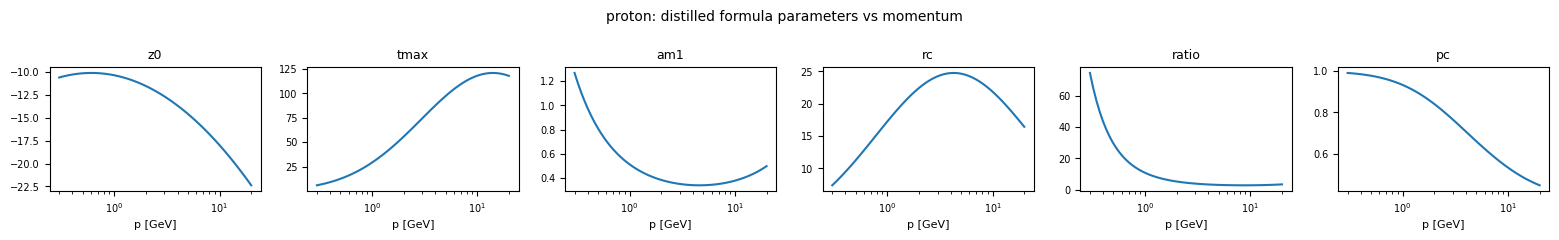

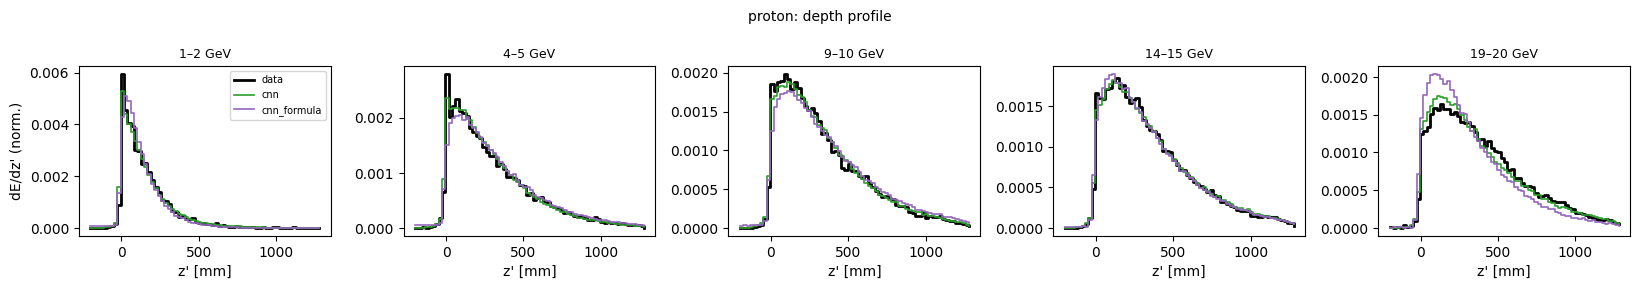

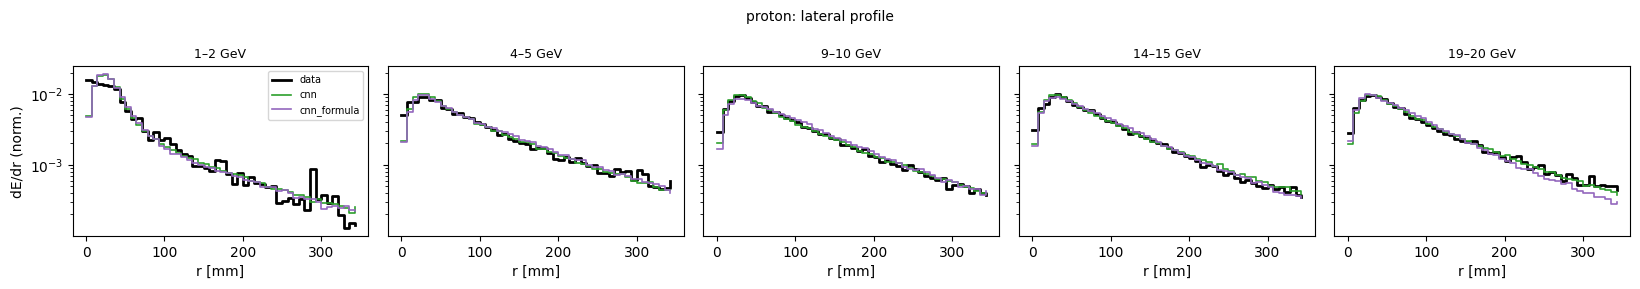

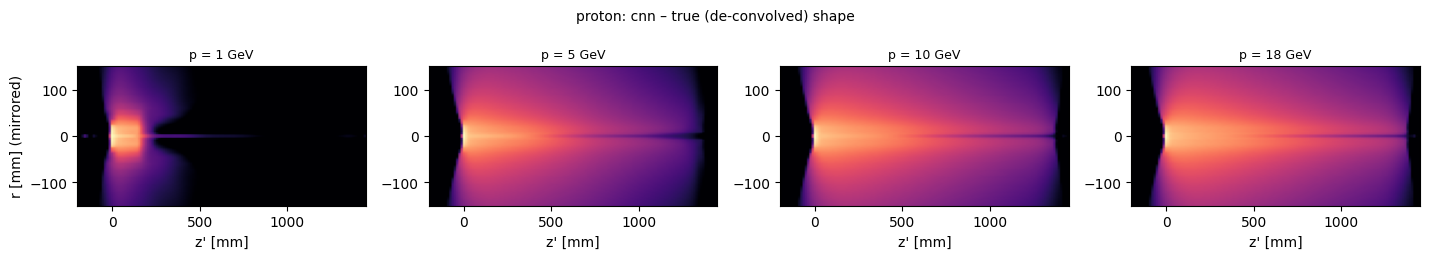

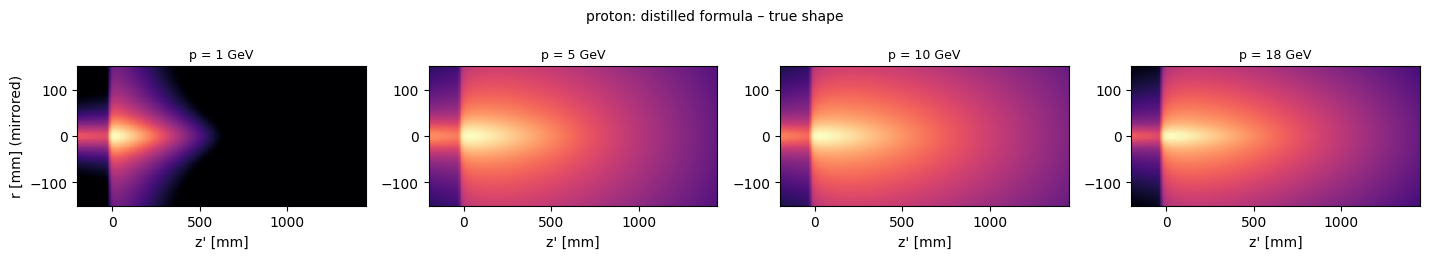

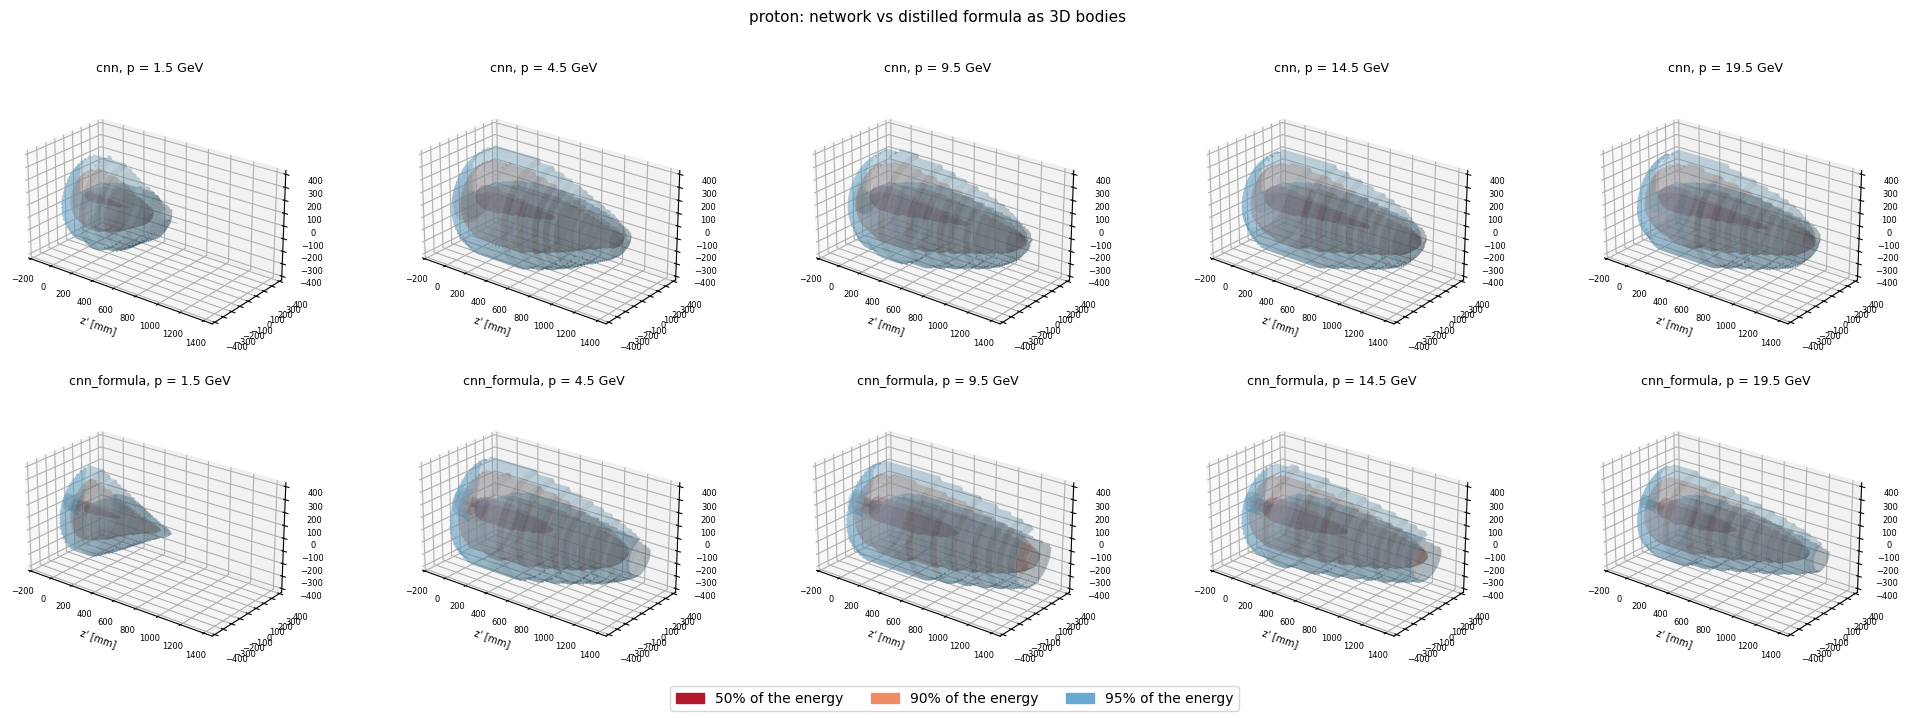

exported proton/cnn: test NLL = 18.1908
exported proton/cnn_formula: test NLL = 18.2662


In [8]:
for particle in PARTICLES:
    display(Markdown(f"## {particle}"))
    data, net, f = DATA[particle], NETS[particle], FORMULAS[particle]
    nll_net, nll_f = test_nll(net, data["test"]), test_nll(f, data["test"])
    gf_path = f"{OUT_DIR}/{particle}/export_gflash.pt"
    for nm in ("mlp", "mlp_formula"):
        pth = f"{OUT_DIR}/{particle}/export_{nm}.pt"
        if os.path.exists(pth):
            print(f"test NLL  {nm} (05): {torch.load(pth, weights_only=False)['test_nll'].mean():.4f}")
    if os.path.exists(gf_path):
        print(f"test NLL  GFlash (01): {torch.load(gf_path, weights_only=False)['test_nll'].mean():.4f}")
    d = nll_f - nll_net
    print(f"test NLL  cnn: {nll_net.mean():.4f}   formula: {nll_f.mean():.4f}   "
          f"difference (paired): {d.mean():+.4f} ± {d.std(ddof=1) / np.sqrt(len(d)):.4f}")
    display(Markdown(f.describe(f"The distilled formula ({f.long} × {f.lat}, degree {f.degree})")))
    formula_curves(f, f"{particle}: distilled formula parameters vs momentum")
    hits = data["test"].hits()
    samples = {"cnn": sample_folded(net, data["test"]), "cnn_formula": sample_folded(f, data["test"])}
    profile_plot(hits, samples, "z", f"{particle}: depth profile")
    profile_plot(hits, samples, "r", f"{particle}: lateral profile")
    shape_map(net, title=f"{particle}: cnn – true (de-convolved) shape")
    shape_map(f, title=f"{particle}: distilled formula – true shape")
    bodies_3d({"cnn": net, "cnn_formula": f}, title=f"{particle}: network vs distilled formula as 3D bodies")
    export(particle, "cnn", net, data)
    export(particle, "cnn_formula", f, data, f.describe(f"CNN → formula ({particle})"))

## 7. Unified comparison: seven shapes with the same metric

Same metric and same plots as in the comparisons of notebooks 03 and 05, with the two new CNN shapes:

| | formula | what it describes | parameters |
|---|---|---|---|
| **GFlash $r_{95}$** (01) | Gamma × (core + tail) | 95% energy region of the **average** shower | ~15–60 (global) |
| **Envelope** (02) | $r = A\,u^{a}e^{-bu}$ | hull sized for 98% of showers | 4 / bin |
| **Drop** (03) | $r = A\,g\!\left(\frac{z'-z_0}{L}\right)$ | same kind of hull, finite, fixed shape | 3 / bin |
| **MLP $r_{95}$** (05) | neural field | 95% energy region of the **average** shower, without a fixed form | network weights (global) |
| **MLP-formula $r_{95}$** (05) | distilled formula | the same, with a formula extracted from the network | formula parameters (global) |
| **CNN $r_{95}$** (06) | convolutional decoder | 95% region of the average shower | network weights (global) |
| **CNN-formula $r_{95}$** (06) | distilled formula | the same, with a formula extracted from the CNN | formula parameters (global) |

**Important for interpreting the metric:** the $r_{95}$ shapes (GFlash, network, formula) are 95% regions of the **average**, de-convolved shower; they were not built for the "95% in 98% of showers" criterion, whereas the envelopes were. Lower coverage and volume of the $r_{95}$ shapes is therefore expected and not a model failure. The volume of the envelope and the drop is the **analytic** volume of the whole body (the same quantity the fit minimises); for $r_{95}$ it is the volume summed on the grid (up to $Z_{MAX}$).

**Common metric in every 1 GeV bin:**
- **Volume** $V$ in litres (for the density models $V = \sum_{z'} \pi\, r_{95}(z')^2\, \Delta z'$ on the grid).
- **Test coverage:** fraction of test showers with at least 95% of their energy inside the shape (points spread within each cell).
  The envelopes are optimised for 0.98; the $r_{95}$ shapes describe the **average** shower, so their coverage is expected to be lower.
- **Thickest point** $z_{env}$ and **maximum radius** $r_{max}$.

GFlash is loaded from `export_gflash.pt`, the envelope from `envelope.pt`, the drop from `drop.pt`, the MLP and MLP-formula from `export_mlp.pt` / `export_mlp_formula.pt` (05); any missing one is skipped.

In [9]:
F_E, F_EV = 0.95, 0.98
G_MAX = 0.5 * 0.75 ** 1.5
zc, z_edges = ZC.cpu().numpy(), Z_EDGES.cpu().numpy()


def deposits(sh, K=8, seed=3):
    # Every hit -> K points inside its (rotated) cell, weight w/K (the same as in 02 and 03).
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def shower_quantile(P, s, f_e=F_E):
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def profile_coverage(P, radius_fn):
    # Fraction of showers keeping >= F_E of their energy inside r <= radius_fn(z').
    inside = torch.as_tensor(P["r"].cpu().numpy() <= radius_fn(P["z"].cpu().numpy()), device=DEVICE)
    s = torch.where(inside, torch.zeros_like(P["r"]), torch.full_like(P["r"], float("inf")))
    return float((shower_quantile(P, s) <= 0).float().mean())


def envelope_r(z, e):
    u = np.clip(np.asarray(z, dtype=float) - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


def drop_radius(z, e):
    t = (np.asarray(z, dtype=float) - e["z0"]) / e["L"]
    return np.where((t > 0) & (t < 1), e["A"] * np.sqrt(np.clip(t, 0, 1)) * np.clip(1 - t, 0, 1) ** 1.5 / G_MAX, 0.0)


@torch.no_grad()
def r95_of(model, p):
    return iso_radius(model(torch.log(torch.tensor([p], device=DEVICE, dtype=torch.float32))).exp()[0].cpu().numpy(), F_E)


def grid_fn(r95):
    # step function on the (z', r) grid, as iso_radius defines it
    return lambda z: np.where((z >= Z_MIN) & (z < Z_MAX), r95[np.clip(np.searchsorted(z_edges, z) - 1, 0, len(r95) - 1)], 0.0)


def stats(radius_fn):
    zz = np.linspace(Z_MIN, Z_MAX, 3301)
    r = radius_fn(zz)
    return {"V_L": float(np.trapezoid(np.pi * r ** 2, zz)) / 1e6, "z_env": float(zz[np.argmax(r)]), "r_max": float(r.max())}


load = lambda name: torch.load(f"{OUT_DIR}/{particle}/{name}", weights_only=False) if os.path.exists(f"{OUT_DIR}/{particle}/{name}") else None
GF = TableModel(load("export_gflash.pt")) if load("export_gflash.pt") is not None else None
ENV, DROP = load("envelope.pt") or {}, load("drop.pt") or {}
TM = lambda name: TableModel(load(f"export_{name}.pt")) if load(f"export_{name}.pt") is not None else None
MODELS = {"GFlash r95": GF, "MLP r95": TM("mlp"), "MLP-formula r95": TM("mlp_formula"), "CNN r95": NETS[particle], "CNN-formula r95": FORMULAS[particle]}
MODELS = {k: v for k, v in MODELS.items() if v is not None}
print("GFlash export:", GF is not None, "| envelope bins:", len(ENV), "| drop bins:", len(DROP))

rows = []
for b in range(20):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    Pte = deposits(data["test"].subset(te))
    pm = float(data["test"].ev["p"][te].mean())
    shapes, grid = {}, {}
    for name, m in MODELS.items():
        grid[name] = r95_of(m, pm)
        shapes[name] = grid_fn(grid[name])
    if b in ENV:
        shapes["envelope"] = lambda z, e=ENV[b]: envelope_r(z, e)
    if b in DROP:
        shapes["drop"] = lambda z, e=DROP[b]: drop_radius(z, e)
    for name, fn in shapes.items():
        s = stats(fn)
        if name == "envelope":                                   # the analytic volume the fit minimises (whole body)
            s["V_L"] = ENV[b]["V_L"]
        if name == "drop":
            s["V_L"] = DROP[b]["V_L"]
        if name in grid:                                        # exact grid volume for the step profiles
            s["V_L"] = float(np.sum(np.pi * grid[name] ** 2) * DZ) / 1e6
        rows.append({"bin": b, "p_mean": pm, "formula": name, **s, "cov_test": profile_coverage(Pte, fn)})
CMP = pd.DataFrame(rows)
ORDER = ["GFlash r95", "envelope", "drop", "MLP r95", "MLP-formula r95", "CNN r95", "CNN-formula r95"]
display(CMP.pivot(index="bin", columns="formula", values=["V_L", "cov_test"]).round(3))
summary = CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean().reindex([o for o in ORDER if o in set(CMP.formula)])
summary["param"] = summary.index.map({"GFlash r95": f"{GF.n_params if GF is not None and hasattr(GF, 'n_params') else '~15–60'} (global)",
                                       "envelope": "4 / bin", "drop": "3 / bin",
                                       "MLP r95": f"{MODELS['MLP r95'].n_params if 'MLP r95' in MODELS else '–'} (global)",
                                       "CNN r95": f"{sum(p.numel() for p in NETS[particle].parameters())} (global)",
                                       "CNN-formula r95": f"{FORMULAS[particle].n_params()} (global)",
                                       "MLP-formula r95": f"{MODELS['MLP-formula r95'].n_params if 'MLP-formula r95' in MODELS else '–'} (global)"})
display(summary.round(3))

GFlash export: True | envelope bins: 20 | drop bins: 20


V_L                                                      \
formula  CNN r95 CNN-formula r95 GFlash r95  MLP r95 MLP-formula r95   
bin                                                                    
0         18.754          16.462     12.931   30.516          28.216   
1        211.519         141.976    164.216  275.248         167.002   
2        443.218         382.232    442.475  465.165         372.739   
3        521.347         529.929    506.775  504.985         492.651   
4        542.430         596.278    512.610  513.179         549.401   
5        543.953         618.606    510.552  512.921         569.716   
6        540.605         620.609    508.752  511.488         571.363   
7        535.416         610.500    509.994  509.710         563.248   
8        530.780         595.678    512.711  506.077         549.583   
9        526.686         577.051    515.085  504.687         533.856   
10       522.520         557.344    517.621  502.738         517.011   
11       520.431         537.099    520.543  501.212         498.794   
12       517.682         516.897    521.997  500.545         480.870   
13       515.632         496.101    523.646  498.736         462.791   
14       514.095         475.517    523.360  498.433         445.281   
15       512.505         455.051    522.885  497.621         428.195   
16       511.639         435.696    521.299  497.124         412.121   
17       510.185         416.356    519.751  496.159         396.399   
18       509.279         398.617    517.454  496.159         381.179   
19       508.467         380.910    514.703  495.856         367.030   

                            cov_test                                     \
formula      drop  envelope  CNN r95 CNN-formula r95 GFlash r95 MLP r95   
bin                                                                       
0         542.185   645.720    0.862           0.845      0.841   0.882   
1        1586.355  1692.674    0.799           0.719      0.750   0.837   
2        1782.461  1962.160    0.772           0.741      0.762   0.784   
3        1922.846  2187.499    0.773           0.748      0.737   0.766   
4        2106.546  2305.933    0.729           0.749      0.695   0.713   
5        1888.045  2083.335    0.748           0.771      0.715   0.735   
6        1786.871  2015.770    0.724           0.752      0.691   0.709   
7        1810.022  2045.767    0.747           0.788      0.727   0.737   
8        1840.272  2159.474    0.723           0.755      0.699   0.711   
9        1919.812  2457.874    0.735           0.755      0.712   0.717   
10       1795.351  2273.396    0.736           0.731      0.701   0.715   
11       1861.086  2240.606    0.757           0.743      0.736   0.743   
12       1730.039  1901.938    0.743           0.719      0.723   0.727   
13       1742.483  2096.365    0.752           0.727      0.740   0.743   
14       1761.644  2060.517    0.765           0.709      0.745   0.752   
15       1642.296  1896.251    0.775           0.695      0.744   0.751   
16       1589.372  1809.849    0.777           0.697      0.768   0.767   
17       1690.281  1862.912    0.761           0.639      0.743   0.748   
18       1460.115  1714.939    0.749           0.620      0.721   0.739   
19       1688.274  1892.390    0.733           0.567      0.721   0.714   

                                         
formula MLP-formula r95   drop envelope  
bin                                      
0                 0.865  0.984    0.980  
1                 0.745  0.981    0.981  
2                 0.736  0.977    0.975  
3                 0.733  0.973    0.969  
4                 0.721  0.979    0.981  
5                 0.755  0.977    0.976  
6                 0.721  0.960    0.960  
7                 0.761  0.977    0.977  
8                 0.731  0.972    0.973  
9                 0.728  0.983    0.985  
10                0.697  0.979    0.977  
11                0.724  0.981    0.977  


,V_L,cov_test,z_env,r_max,param
formula,,,,,
GFlash r95,469.968,0.733,85.100,396.597,45 (global)
envelope,1965.268,0.976,303.100,751.476,4 / bin
drop,1707.318,0.977,414.625,722.082,3 / bin
MLP r95,465.928,0.749,159.300,402.453,881 (global)
MLP-formula r95,439.372,0.701,123.800,385.673,21 (global)
CNN r95,477.857,0.758,181.850,403.996,121939 (global)
CNN-formula r95,467.945,0.723,109.650,390.451,21 (global)


**What to look for in the table and plots:**
- **MLP $r_{95}$ vs. GFlash $r_{95}$:** both are the 95% region of the average shower. If they are close, the GFlash functional form is
  good enough; where they differ (e.g. shower start, lateral tail), the network learned something the formula cannot describe.
- **CNN vs. MLP:** two different networks on the same data; if their $r_{95}$ are close, the shape is not an artefact of the architecture.
- **CNN-formula vs. CNN, MLP-formula vs. MLP:** if the $r_{95}$ and coverage of the distilled formula are close to those of the network, distillation lost no essential information.
- **Density vs. envelope:** the coverage of the three $r_{95}$ shapes is expected to stay well below 0.98, that of the two envelopes ~0.98. This reflects the two approaches, not an error.

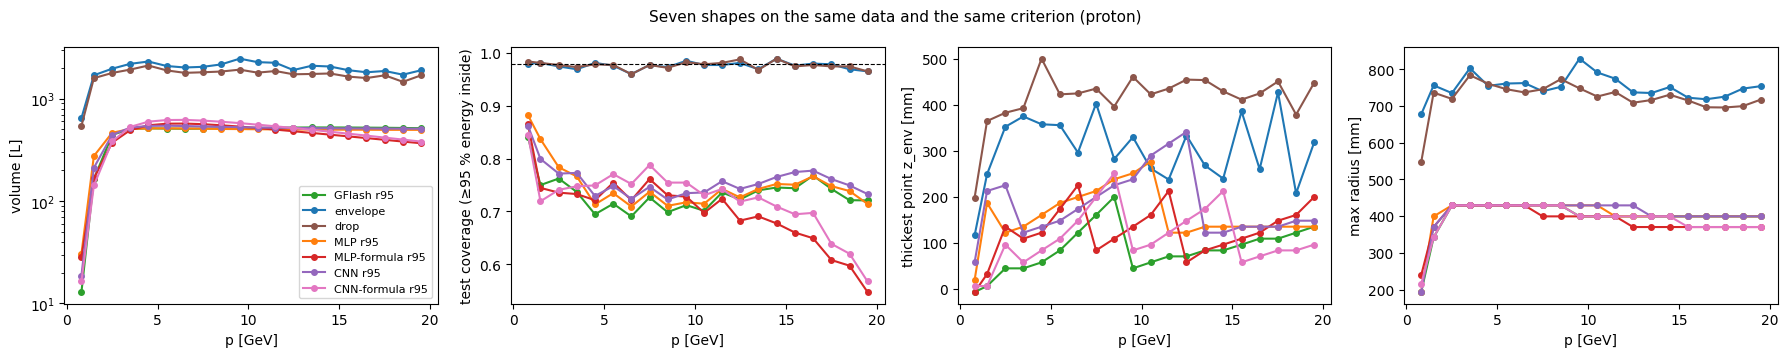

In [10]:
colors = {"GFlash r95": "tab:green", "envelope": "tab:blue", "drop": "tab:brown", "MLP r95": "tab:orange", "MLP-formula r95": "tab:red", "CNN r95": "tab:purple", "CNN-formula r95": "tab:pink"}
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for name in [o for o in ORDER if o in set(CMP.formula)]:
    g = CMP[CMP.formula == name]
    for a_, col in zip(ax, ["V_L", "cov_test", "z_env", "r_max"]):
        a_.plot(g.p_mean, g[col], "o-", c=colors[name], label=name, ms=4)
for a_, lab in zip(ax, ["volume [L]", "test coverage (≥95 % energy inside)", "thickest point z_env [mm]", "max radius [mm]"]):
    a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[1].axhline(F_EV, c="k", lw=0.8, ls="--"); ax[0].legend(fontsize=8)
fig.suptitle("Seven shapes on the same data and the same criterion (proton)", fontsize=11)
plt.tight_layout(); plt.show()

### 2D map with $(z', r)$ axes, in the same form as the comparison plots of 03 and 05

- **Background:** mean energy density of the training data in the given 1 GeV bin ($\log_{10}$, $r$ mirrored).
- **Green dotted:** GFlash $r_{95}$. **Blue:** envelope. **White:** drop. **Orange:** MLP $r_{95}$. **Red dashed:** MLP-formula $r_{95}$. **Violet:** CNN $r_{95}$. **Pink dashed:** CNN-formula $r_{95}$.

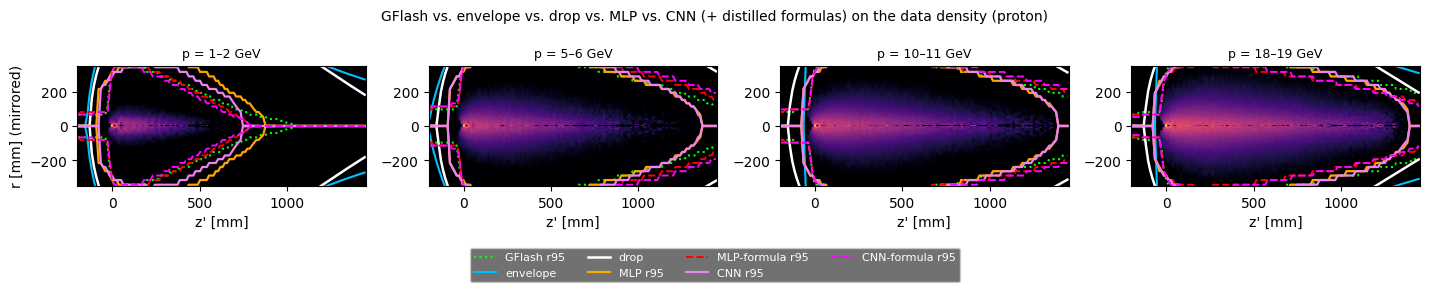

In [11]:
STYLE = {"GFlash r95": dict(c="lime", ls=":", lw=1.5), "envelope": dict(c="deepskyblue", lw=1.5), "drop": dict(c="white", lw=1.8),
         "MLP r95": dict(c="orange", lw=1.6), "MLP-formula r95": dict(c="red", ls="--", lw=1.4),
         "CNN r95": dict(c="violet", lw=1.6), "CNN-formula r95": dict(c="magenta", ls="--", lw=1.4)}


def compare_map(sh, p_values=(1, 5, 10, 18), r_show=350, title=""):
    rc_ = RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.8))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[z_edges, R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc_, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        curves = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
        if b in ENV:
            curves["envelope"] = envelope_r(zc, ENV[b])
        if b in DROP:
            curves["drop"] = drop_radius(zc, DROP[b])
        for name in ORDER:
            if name in curves:
                ax.plot(zc, curves[name], **STYLE[name]); ax.plot(zc, -curves[name], **STYLE[name])
        ax.set_ylim(-r_show, r_show); ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9); ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], label=n, **STYLE[n]) for n in ORDER if n in set(CMP.formula)]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    plt.show()


compare_map(data["train"], title="GFlash vs. envelope vs. drop vs. MLP vs. CNN (+ distilled formulas) on the data density (proton)")

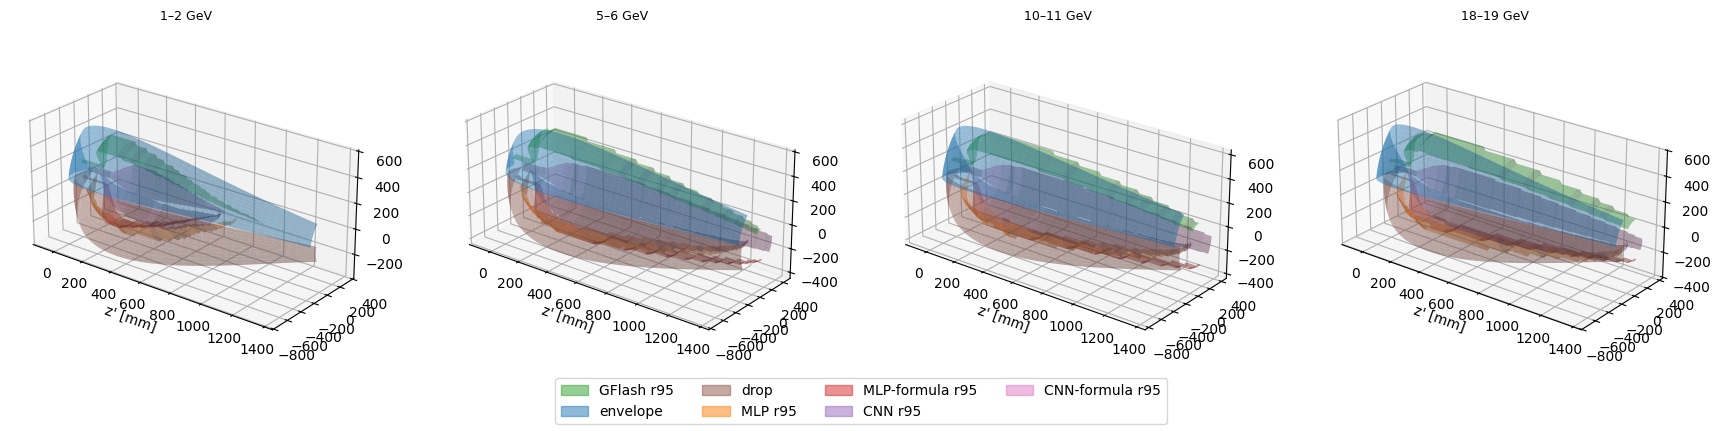

saved: comparison_7shapes.csv


In [12]:
# the five bodies side by side in 3D: each body in its own sector, so all of them stay visible
show = [1, 5, 10, 18]
fig = plt.figure(figsize=(4.4 * len(show), 4.2))
for j, b in enumerate(show):
    ax_ = fig.add_subplot(1, len(show), j + 1, projection="3d")
    bodies = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
    if b in ENV:
        bodies["envelope"] = envelope_r(zc, ENV[b])
    if b in DROP:
        bodies["drop"] = drop_radius(zc, DROP[b])
    names = [n for n in ORDER if n in bodies]
    for k, name in enumerate(names):
        f0 = 0.5 * np.pi + 1.5 * np.pi * k / len(names); f1 = 0.5 * np.pi + 1.5 * np.pi * (k + 1) / len(names)
        ax_.plot_surface(*revolve(zc, bodies[name], f0, f1, 12), color=colors[name], alpha=0.45, linewidth=0)
    ax_.set_xlim(-150, 1450); ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
    ax_.set_title(f"{b}–{b + 1} GeV", fontsize=9); ax_.set_xlabel("z' [mm]")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[n], alpha=0.5, label=n) for n in ORDER if n in set(CMP.formula)], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
CMP.to_csv(f"{OUT_DIR}/{particle}/comparison_7shapes.csv", index=False)
print("saved: comparison_7shapes.csv")

## 8. The shape-form-particle formula, fitted directly to the data

shape-form-particle builds the average shower shape from physically separate terms – shower + axial term of the primary particle
(range, attenuation, multiple-scattering widening, Bragg rise) + entry spike + end-of-range blob + far halo, see `../ALL-README.md` –
and fits every parameter (a polynomial in ln T) **directly to the simulated hits** by maximum likelihood, with the detector folding of
this notebook. Sections 5–7 distil the network: a few formula families are fitted to the network's maps; here the network is only the benchmark. Nothing is fitted here: the saved final models (`../results/particles/<particle>/`) are loaded and evaluated
on this notebook's test set.

Two metrics:
- **Report metric** (this notebook's `test_nll`). The formula is multiplied by the parameter-free template Ā(z', r), the detector
  acceptance averaged over the incidence angles (the tilted entrance face cuts the body of revolution). The fair reference is the
  report's baseline refitted with the same template ("old formula × Ā").
- **3D metric** of shape-form-particle: the likelihood normalised per event to its own detector slab (between the tilted entrance face
  and the back face). Only models trained in this metric are compared in it: the old formula, the new formula and the MLP, each refitted
  or fine-tuned in 3D.

"saved" next to a recomputed value is the report's own export (before this run) or the number of shape-form-particle (`test_v3.json`).

In [13]:
import json
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))  # particle_shape.py, shapelab.py, protonlab.py
import protonlab
import shapelab

particle = PARTICLES[0]
data = DATA[particle]
OUR = os.path.abspath(os.path.join("..", "results", "particles", particle))   # saved final models of shape-form-particle
PIPE = json.load(open(f"{OUR}/test_v3.json"))                   # its saved test-set numbers (both metrics)
REPORT_SAVED = {'gflash': 18.253603, 'mlp': 18.192236, 'mlp_formula': 18.267671, 'cnn': 18.190821, 'cnn_formula': 18.266161}                                 # the report's saved test NLLs (its exports, before this run)
c0, s0 = shapelab.lnp_center_scale(data)
base_name, base_long, _ = shapelab.REPORT_BASE[particle]       # the report's baseline: GFlash, or the cylinder for the muon
_arch = pd.read_csv(f"{OUT_DIR}/{particle}/mlp_architecture.csv").drop_duplicates("config", keep="last")
_row = _arch[_arch.chosen == "◀"].iloc[-1]
H_MLP, L_MLP = int(_row.hidden), int(_row.n_layers)            # architecture of the report's chosen MLP


def ours(kind, metric, C):
    """A saved model of shape-form-particle: 'new' (the final formula), 'base' (the report's baseline refitted), 'mlp' (the report's
    MLP fine-tuned); metric 'std' = report metric (× Ā), 'slab' = 3D metric."""
    if kind == "new":
        return shapelab.build_final(C, particle, OUR, c0, s0, metric=metric)[0]
    n = PIPE["degrees"][f"base_{metric}"]
    st = torch.load(f"{OUR}/{kind}_{metric}" + (f"_n{n}" if kind == "base" else "") + ".pt", map_location=DEVICE,
                    weights_only=False)["state"]
    if kind == "mlp":
        m = FieldModel(H_MLP, L_MLP)
    else:
        m = Formula(base_long, "core_tail", degree=n, lnp0=c0, lnp_s=s0)
        m = shapelab.WithAcceptance(m, torch.ones(N_Z, N_R)) if metric == "std" else m
        st = {("base." + k[7:] if k.startswith("base.f.") else k[2:] if k.startswith("f.") else k): v for k, v in st.items()}
    m.load_state_dict(st)
    return m.to(DEVICE).eval()


def table(nll, params, saved, ref):
    """Test NLL recomputed here, the saved value, and the paired difference to `ref` (± standard error)."""
    rows = []
    for k, v in nll.items():
        d = np.asarray(nll[ref], dtype=np.float64) - np.asarray(v, dtype=np.float64)
        rows.append({"model": k, "parameters": params[k], "test NLL (here)": float(np.mean(v)), "saved": saved.get(k, np.nan),
                     f"{ref} − model": float(d.mean()), "± SE": float(d.std(ddof=1) / np.sqrt(len(d)))})
    return pd.DataFrame(rows).set_index("model")


def gap_line(m_, key_new, key_old, key_net, saved_gap):
    gap = (m_[key_old] - m_[key_new]) / (m_[key_old] - m_[key_net])
    print(f"gap closed: {100 * gap:.0f} % (saved: {100 * saved_gap:.0f} %);  the new formula reaches "
          f"{100 * np.exp(m_[key_net] - m_[key_new]):.1f} % of the fine-tuned network's likelihood per deposit")

### 8.1 Accuracy in the report metric

All models on the same test events. Gap closed = (old formula × Ā − new formula) / (old formula × Ā − fine-tuned MLP).

In [14]:
new_std, base_std, mlp_std = (ours(k, "std", globals()) for k in ("new", "base", "mlp"))
NET, FORM = NETS[particle], FORMULAS[particle]                 # the report's CNN and its distilled formula (sections 4–5)
ex_base = torch.load(f"{OUT_DIR}/{particle}/export_{base_name}.pt", weights_only=False)
nll = {f"report baseline ({base_name})": ex_base["test_nll"], "report CNN": nll_net, "report CNN-distilled formula": nll_f}
saved = {f"report baseline ({base_name})": REPORT_SAVED[base_name], "report CNN": REPORT_SAVED["cnn"],
         "report CNN-distilled formula": REPORT_SAVED["cnn_formula"]}
params = {f"report baseline ({base_name})": ex_base["n_params"], "report CNN": sum(p.numel() for p in NET.parameters()),
          "report CNN-distilled formula": FORM.n_params()}
if "cnn" == "cnn":                                          # the CNN notebook also shows the report's MLP (05)
    nll["report MLP"], saved["report MLP"], params["report MLP"] = test_nll(MLP, data["test"]), REPORT_SAVED["mlp"], sum(p.numel() for p in MLP.parameters())
nll.update({"old formula × Ā (refit)": test_nll(base_std, data["test"]), "new formula × Ā": test_nll(new_std, data["test"]),
            "MLP fine-tuned": test_nll(mlp_std, data["test"])})
saved.update({"old formula × Ā (refit)": PIPE["nll"]["std:base_acc"], "new formula × Ā": PIPE["nll"]["std:new"], "MLP fine-tuned": PIPE["nll"]["std:mlp_ft"]})
params.update({"old formula × Ā (refit)": base_std.n_params(), "new formula × Ā": new_std.n_params(),
               "MLP fine-tuned": sum(p.numel() for p in mlp_std.parameters())})
display(table(nll, params, saved, "new formula × Ā").round(4))
m_ = {k: float(np.mean(v)) for k, v in nll.items()}
gap_line(m_, "new formula × Ā", "old formula × Ā (refit)", "MLP fine-tuned", PIPE["gap_closed"]["std:new"])

,parameters,test NLL (here),saved,new formula × Ā − model,± SE
model,,,,,
report baseline (gflash),45,18.2536,18.2536,-0.0596,0.0020
report CNN,121939,18.1908,18.1908,0.0032,0.0005
report CNN-distilled formula,21,18.2662,18.2662,-0.0721,0.0021
report MLP,881,18.1922,18.1922,0.0018,0.0005
old formula × Ā (refit),45,18.2331,18.2331,-0.0391,0.0016
new formula × Ā,143,18.1940,18.1940,0.0000,0.0000
MLP fine-tuned,881,18.1898,18.1898,0.0042,0.0004


gap closed: 90 % (saved: 90 %);  the new formula reaches 99.6 % of the fine-tuned network's likelihood per deposit


### 8.2 Accuracy in the 3D metric (shape-form-particle's own metric)

The same test events with the likelihood normalised to each event's detector slab. A fresh copy of the unchanged common code is used,
with only `event_nll` replaced by its slab-normalised version (`shapelab.SLAB_NLL_SRC`).

In [15]:
C3 = protonlab.load_common_for(particle, OUT_DIR=OUT_DIR)       # the 00_common definitions in a separate namespace ...
exec(shapelab.SLAB_GEOM_SRC, C3)
exec(shapelab.SLAB_NLL_SRC, C3)                                  # ... with the likelihood normalised to each event's detector slab
names = {"old formula (3D refit)": "base", "new formula": "new", "MLP fine-tuned (3D)": "mlp"}
models3 = {k: ours(v, "slab", C3) for k, v in names.items()}
nll3 = {k: C3["test_nll"](m, data["test"]) for k, m in models3.items()}
params3 = {k: (m.n_params() if hasattr(m, "n_params") else sum(p.numel() for p in m.parameters())) for k, m in models3.items()}
saved3 = dict(zip(nll3, [PIPE["nll"]["slab:base"], PIPE["nll"]["slab:new"], PIPE["nll"]["slab:mlp_ft"]]))
display(table(nll3, params3, saved3, "new formula").round(4))
m3 = {k: float(np.mean(v)) for k, v in nll3.items()}
gap3 = (m3["old formula (3D refit)"] - m3["new formula"]) / (m3["old formula (3D refit)"] - m3["MLP fine-tuned (3D)"])
print(f"gap closed (3D): {100 * gap3:.0f} % (saved: {100 * PIPE['gap_closed']['slab:new']:.0f} %)")
if particle == "pion":
    print("note: the pion's 3D MLP is degenerate (almost all of its mass lies outside the detector slabs), so the 3D gap is not reliable")

device: cuda | data: /home/user/data/simulations/regression-proton/ | output: results


,parameters,test NLL (here),saved,new formula − model,± SE
model,,,,,
old formula (3D refit),45,18.2003,18.2003,-0.0343,0.0015
new formula,143,18.1660,18.1660,0.0000,0.0000
MLP fine-tuned (3D),881,18.1614,18.1614,0.0047,0.0005


gap closed (3D): 88 % (saved: 88 %)


### 8.3 The fitted formula

The formula of this particle with the fitted values (3D metric), as written in `../ALL-README.md` (all coefficients:
`../results/particles/<particle>/formula_coefficients_slab.csv`; the full card: `formula.md` in the same folder).

In [16]:
name = {"electron": "Electron", "muon": "Muon", "pion": "Pion", "proton": "Proton"}[particle]
txt = open(os.path.join("..", "ALL-README.md"), encoding="utf-8").read()
i = txt.index(f"**{name}** (m =")
display(Markdown(txt[i:min(k for k in (txt.find("\n**", i + 5), txt.find("<!-- KEPLETEK:END", i)) if k > 0)]))

**Proton** (m = 938.3 MeV; polynomial degree and number of parameters: n = 6, 143)

`ρ(z', r | p) = w_zápor·S + w_nyom·U + w_csúcs·D + w_folt·E + w_távoli·H`

- Shower depth profile, plateau: `L(z') ∝ σ((z' − z_s)/w1)·σ((ℓ − z')/w2)·e^(κ·z'/1 m)` (values below).
- Shower cross-section: `T(r│z') = f_core·Gauss(r; σ) + f_body·Cauchy(r; R) + f_halo·e^(−r/λ)/(2πλ(r + 1 mm))`; σ, R, λ and the fractions vary with depth (below at z' = 100 mm).
- Axial term: range `R(T) = 757 mm · (T/GeV)^1.78 − 36.5 mm` (smoothly floored at ~1 mm); start `σ((z' − 24.1 mm)/4 mm)`, end `σ((R − z')/w_R)` with w_R = 0.0579·R + 3 mm; attenuation `e^(−z'/266 mm)·e^(−2.46·z'/R)`; Bragg rise `(1 − z'/R + 0.03)^(−0.804)`; width `σ(z')² = (18.5 mm)² + (285 mm · (z'/1 m)^2.37 / βp)²`; delta-electron halo `e^(−r/81.5 mm)/(2π·81.5 mm·(r + 1 mm))` (its share below).
- End-of-range blob: Gaussian, σ_z = 76.3 mm, σ_r = 81.1 mm.
- Entry spike: Gaussian (position and widths below). Far halo: `H ∝ σ(z'/10 mm)·e^(−z'/962 mm)/(r + 1 cm)`.

| | p = 1 GeV/c | p = 5 GeV/c | p = 20 GeV/c |
|---|---:|---:|---:|
| T (kinetic energy) | 0.433 GeV | 4.15 GeV | 19.1 GeV |
| energy share: shower | 14.9% | 73.6% | 81.1% |
| energy share: track | 60.5% | 21.1% | 16.8% |
| energy share: spike | 23.6% | 4.87% | 2.12% |
| energy share: blob | 0.671% | < 0.01% | < 0.01% |
| energy share: far halo | 0.383% | 0.408% | < 0.01% |
| shower start z_s / rise w1 | −7.12 / 123 mm | 22.3 / 86.3 mm | 80.7 / 80.2 mm |
| shower end ℓ / fall-off w2 | 132 / 198 mm | 863 / 378 mm | 1330 / 76.2 mm |
| slow slope κ | −3.02 /m | −2.72 /m | −2.65 /m |
| core σ / Cauchy R / halo λ (z' = 100 mm) | 84.4 / 121 / 227 mm | 58.8 / 71 / 207 mm | 38.9 / 77.6 / 203 mm |
| fractions core / body / halo (z' = 100 mm) | 0.08 / 0.87 / 0.05 | 0.08 / 0.80 / 0.13 | 0.13 / 0.76 / 0.10 |
| axial-term range R(T) | 135 mm | 9485 mm | 143749 mm |
| delta-halo share | 3.94% | 33.4% | 20.4% |
| spike position / σ_z / σ_r | −3.17 / 13.7 / 10.1 mm | −7.75 / 22.1 / 11.5 mm | −18.5 / 23.8 / 11.6 mm |


### 8.4 Profiles and the true shape

The profile plots of this notebook, now with the new formula (report metric, × Ā), and the true (de-convolved) shape of the formula.

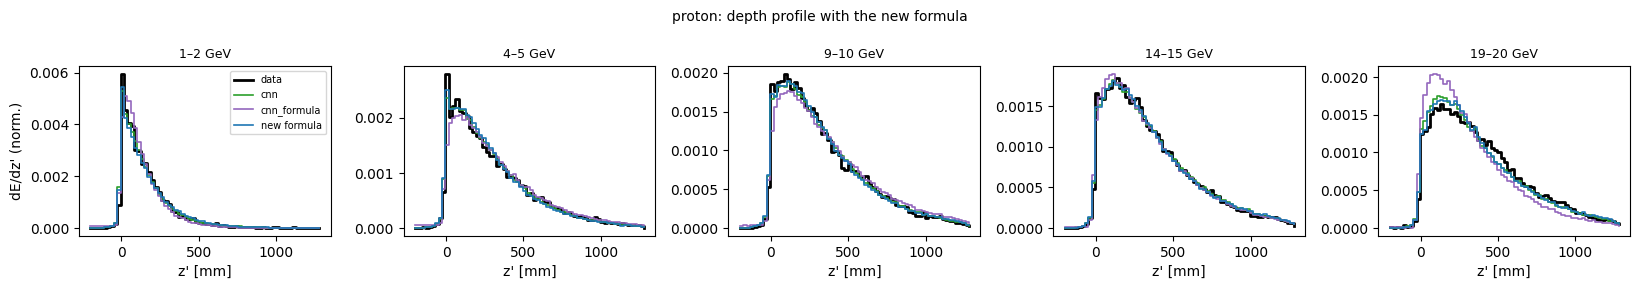

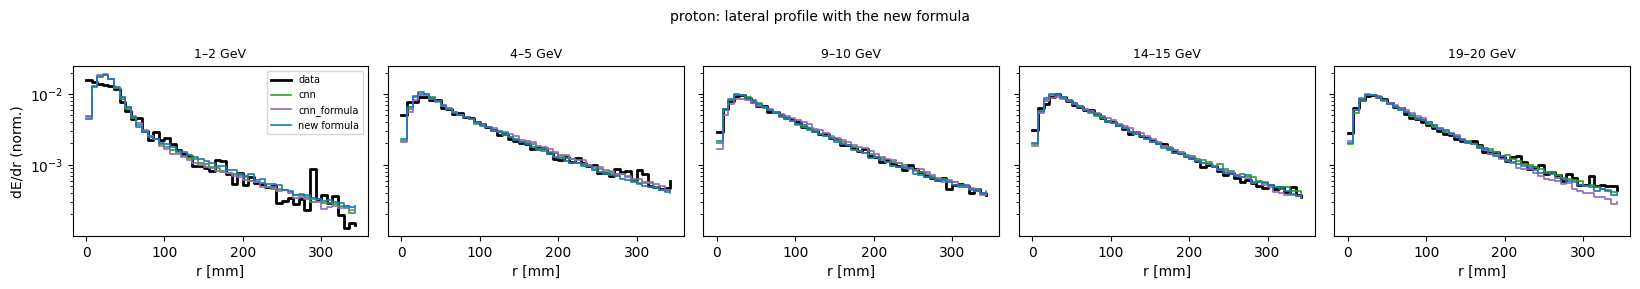

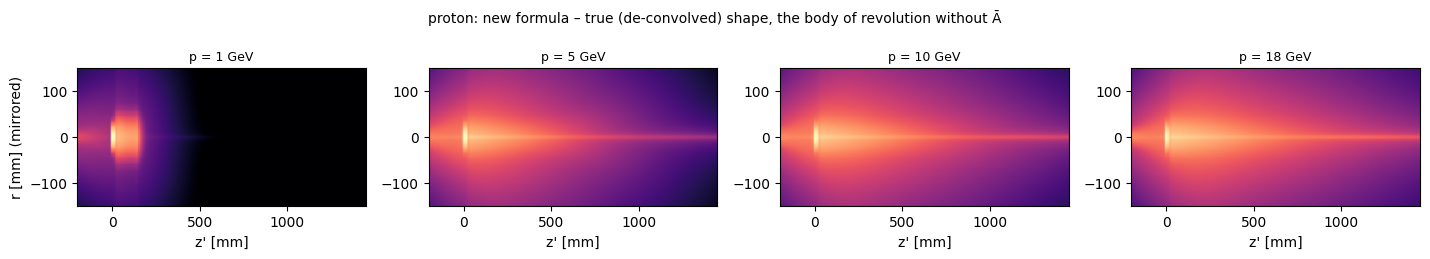

In [17]:
COLORS["new formula"] = "tab:blue"
samples["new formula"] = sample_folded(new_std, data["test"])
profile_plot(hits, samples, "z", f"{particle}: depth profile with the new formula")
profile_plot(hits, samples, "r", f"{particle}: lateral profile with the new formula")
shape_map(new_std.base, title=f"{particle}: new formula – true (de-convolved) shape, the body of revolution without Ā")

### 8.5 The r95 region in the unified comparison of section 7

The 95 % region of the new formula's average map (the same definition and coverage test as for the network), added to the
comparison table and the 2D map of section 7.

,V_L,cov_test,z_env,r_max
formula,,,,
GFlash r95,469.968,0.733,85.100,396.597
envelope,1965.268,0.976,303.100,751.476
drop,1707.318,0.977,414.625,722.082
MLP r95,465.928,0.749,159.300,402.453
MLP-formula r95,439.372,0.701,123.800,385.673
CNN r95,477.857,0.758,181.850,403.996
CNN-formula r95,467.945,0.723,109.650,390.451
new formula r95,494.415,0.767,216.025,419.109


saved (shape-form-particle, r95 new formula): V = 494.4 L, coverage 0.77


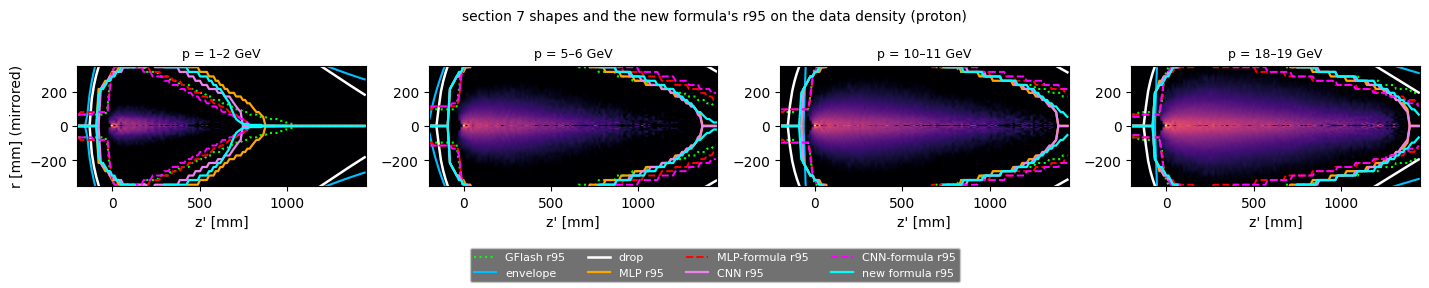

In [18]:
rows = []
for b in range(20):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    pm = float(data["test"].ev["p"][te].mean())
    r95 = r95_of(new_std, pm)
    rows.append({"bin": b, "p_mean": pm, "formula": "new formula r95", **stats(grid_fn(r95)),
                 "V_L": float(np.sum(np.pi * r95 ** 2) * DZ) / 1e6, "cov_test": profile_coverage(deposits(data["test"].subset(te)), grid_fn(r95))})
CMP = pd.concat([CMP, pd.DataFrame(rows)], ignore_index=True)
MODELS["new formula r95"] = new_std
ORDER = ORDER + ["new formula r95"]
STYLE["new formula r95"] = dict(c="cyan", lw=1.6)
colors["new formula r95"] = "tab:cyan"
display(CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean().reindex([o for o in ORDER if o in set(CMP.formula)]).round(3))
sh_ = {s["shape"]: s for s in json.load(open(f"{OUR}/shapes.json"))["shapes"]}
print(f"saved (shape-form-particle, r95 new formula): V = {sh_['r95 new formula']['V']:.1f} L, coverage {sh_['r95 new formula']['cov']:.2f}")
compare_map(data["train"], title=f"section 7 shapes and the new formula's r95 on the data density ({particle})")

**What to look for:** the recomputed test NLLs agree with the saved numbers; the new formula lies between the old formula and the
network and closes most of the gap; in the profiles it follows the data where a single shower term cannot (primary particle, entrance,
lateral tail).